# KMOS Pipeline — Best Detections Showcase

Ranks every IFU across all downloaded OBs in `kmos_ob_proc_server/` by
H$\alpha$ signal-to-noise and presents the top detections in a gallery.
All data are from the **server run** (telluric-corrected, zapv2 sky subtraction,
2D background removal, radial-velocity shift).

**Sections**
1. Imports and configuration
2. Helper functions
3. Load all IFUs — compute H$\alpha$ SNR ranking
4. Gallery — top detections (H$\alpha$ zoom)
5. Detail view — full spectrum + spatial maps for the best targets

In [1]:
import glob, os, csv, pathlib, warnings
from collections import defaultdict

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from astropy.io import fits

# ── configuration ─────────────────────────────────────────────────────────────
BASE         = "kmos_ob_proc_server" # "kmos_ob_proc_local"#    # directory with pipeline output
SUFFIX       = "_s_i_bkg2d_rv.fits"    # final pipeline product
APERTURE     = 5                        # extraction box side (spaxels)
EDGE_MARGIN  = 4                        # NaN-gap erosion margin

# Hα-peak centring
HA_REST          = 0.65628   # µm
MAX_CENTER_OFFSET = 4.0      # px — if Hα peak is farther from IFU centre than
                             # this, fall back to geometric centre (likely a sky
                             # artefact or edge hit, not the galaxy)

# SNR metric
SNR_WIN_HALF  = 0.0025    # ±µm signal window around Hα
SNR_CONT_IN   = 0.006     # inner edge of continuum window
SNR_CONT_OUT  = 0.022     # outer edge of continuum window
SNR_MIN       = 2.0       # minimum SNR to include in gallery

TOP_N        = 50         # max panels in gallery
TOP_DETAIL   = 6          # targets for the detail-view section
GALLERY_HALF = 0.018      # ±µm around Hα in all zoom panels

PALETTE = [
    "#1a6faf", "#c03a2b", "#27ae60", "#8e44ad", "#d35400",
    "#16a085", "#2c3e50", "#e74c3c", "#2980b9", "#1abc9c",
    "#f39c12", "#7f8c8d", "#6c3483", "#1e8449", "#922b21",
    "#0e6655", "#784212", "#1b4f72", "#f1c40f", "#8e44ad",
    "#3498db", "#e67e22", "#2ecc71", "#9b59b6", "#e74c3c",
    "#34495e", "#f39c12", "#2c3e50", "#d35400", "#16a085",
    "#2980b9", "#c0392b", "#27ae60", "#8e44ad", "#f1c40f",
    "#7f8c8d", "#1abc9c", "#e67e22", "#2c3e50", "#3498db",
    "#8e44ad", "#d35400", "#16a085", "#c03a2b", "#27ae60",
    "#922b21", "#1e8449", "#1b4f72", "#784212", "#0e6655",
]

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 9,
    "axes.titlesize": 9, "axes.titleweight": "bold", "axes.titlepad": 5,
    "axes.labelsize": 8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#444", "axes.linewidth": 0.8,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": "#bbb", "grid.alpha": 0.3, "grid.linewidth": 0.5,
    "figure.facecolor": "white", "savefig.facecolor": "white",
    "figure.dpi": 120,
})

In [2]:
# ── data helpers (self-contained, mirrors kmos_reduction_check.ipynb) ──────────
def wavelength_axis(hdr):
    return (np.arange(hdr["NAXIS3"]) + 1 - hdr["CRPIX3"]) * hdr["CDELT3"] + hdr["CRVAL3"]

def active_ifus(hdul):
    return [i for i in range(1, 25)
            if hdul[i].data is not None and np.ndim(hdul[i].data) == 3]

def _erode_valid(finite, margin):
    inv = ~finite
    eroded = inv.copy()
    for s in range(1, margin + 1):
        eroded[s:]  |= inv[:-s]
        eroded[:-s] |= inv[s:]
    return ~eroded

def aperture_spectrum(hdul, ifu, center, box=APERTURE, margin=EDGE_MARGIN):
    cube  = np.array(hdul[ifu].data)
    hdr   = hdul[ifu].header
    py, px = center
    h2    = box // 2
    y0, y1 = max(py - h2, 0), min(py + h2 + 1, cube.shape[1])
    x0, x1 = max(px - h2, 0), min(px + h2 + 1, cube.shape[2])
    patch  = cube[:, y0:y1, x0:x1].reshape(cube.shape[0], -1)
    valid  = _erode_valid(np.isfinite(patch), margin)
    cleaned = np.where(valid, patch, np.nan)
    rows_ok = valid.any(axis=1)
    spec    = np.full(cube.shape[0], np.nan)
    spec[rows_ok] = np.nansum(cleaned[rows_ok], axis=1)
    return wavelength_axis(hdr), spec

def ifu_center(cube):
    return (cube.shape[1] // 2, cube.shape[2] // 2)

def find_exposures(base=BASE, suffix=SUFFIX):
    result = defaultdict(list)
    for path in sorted(glob.glob(os.path.join(base, "*", "science", f"*{suffix}"))):
        parts = path.replace("\\", "/").split("/")
        ob    = parts[-3]
        with fits.open(path) as h:
            band = h[0].header.get("HIERARCH ESO INS GRAT1 ID", "??")
        result[(ob, band)].append(path)
    return dict(result)

EMISSION_LINES = {
    "[OII]": 0.37270, "Hβ": 0.48627, "[OIII]5007": 0.50082,
    "Hα": 0.65628, "[NII]6583": 0.65835,
}
LINE_COLORS = {
    "[OII]": "#e377c2", "Hβ": "#1f77b4", "[OIII]5007": "#17becf",
    "Hα": "#d62728", "[NII]6583": "#ff7f0e",
}

# ── redshift catalogue ────────────────────────────────────────────────────────
_Z_TABLE, _Z_TYPE, _Z_QUALITY = {}, {}, {}
_Z_CSV = pathlib.Path("scripts") / "target_redshifts.csv"
if _Z_CSV.exists():
    with open(_Z_CSV, newline="", encoding="utf-8") as _f:
        for _row in csv.DictReader(_f):
            if (_row.get("redshift") or "").strip():
                _key = (_row["field"].strip(), _row["arm_target_id"].strip())
                _Z_TABLE[_key] = float(_row["redshift"].strip())
                _Z_TYPE[_key]  = (_row.get("redshift_type") or "").strip()
                _q = (_row.get("quality") or "").strip()
                _Z_QUALITY[_key] = float(_q) if _q and _q != "nan" else np.nan
    print(f"Loaded {len(_Z_TABLE)} redshifts  "
          f"(spec: {sum(1 for v in _Z_TYPE.values() if v=='spec')}, "
          f"photo: {sum(1 for v in _Z_TYPE.values() if v=='photo')})")
else:
    print(f"WARNING: {_Z_CSV} not found — emission lines will not be drawn")

def get_z_meta(hdul, ifu):
    hdr0  = hdul[0].header
    field = (hdr0.get("ESO OBS TARG NAME") or "").strip()
    key   = f"ESO OCS ARM{ifu} NAME"
    tid   = str(hdr0.get(key) or hdr0.get(f"HIERARCH {key}") or "").strip()
    if not field or not tid:
        return None, "", np.nan
    k = (field, tid)
    return _Z_TABLE.get(k), _Z_TYPE.get(k, ""), _Z_QUALITY.get(k, np.nan)

Loaded 99 redshifts  (spec: 38, photo: 61)


In [3]:
def ha_peak_center(cube, wave, z, margin=EDGE_MARGIN, min_nbr=0.08):
    """
    Peak spaxel in the Hα narrow-band image (±3 spectral pixels).
    Rejects isolated hot pixels: neighbours must average ≥ min_nbr × peak.
    Always returns the full ha_image for display regardless of which centre is chosen.
    The caller applies MAX_CENTER_OFFSET to decide whether to actually use the peak.
    """
    ha_obs = HA_REST * (1.0 + z)
    hp     = int(np.argmin(np.abs(wave - ha_obs)))
    p0, p1 = max(hp - 3, 0), min(hp + 4, cube.shape[0])
    valid  = _erode_valid(np.isfinite(cube[p0:p1]), margin)
    ha_im  = np.nansum(np.where(valid, cube[p0:p1], np.nan), axis=0)
    ny, nx = ha_im.shape

    flat  = ha_im.ravel()
    order = np.argsort(np.where(np.isfinite(flat), flat, -np.inf))[::-1]
    for idx in order:
        v = flat[idx]
        if not np.isfinite(v) or v <= 0:
            break
        py, px = np.unravel_index(idx, (ny, nx))
        nbrs = [ha_im[py+dy, px+dx]
                for dy in (-1, 0, 1) for dx in (-1, 0, 1)
                if (dy, dx) != (0, 0) and 0 <= py+dy < ny and 0 <= px+dx < nx]
        nbrs = [n for n in nbrs if np.isfinite(n)]
        if nbrs and np.mean(nbrs) >= min_nbr * v:
            return (py, px), ha_im
    return ifu_center(cube), ha_im


def ha_snr(wave, spec, z):
    """Continuum-subtracted peak Hα SNR, MAD-based noise."""
    ha = HA_REST * (1.0 + z)
    if not (wave.min() < ha < wave.max()):
        return np.nan
    sig_mask  = np.abs(wave - ha) <= SNR_WIN_HALF
    cont_mask = ((np.abs(wave - ha) >= SNR_CONT_IN) &
                 (np.abs(wave - ha) <= SNR_CONT_OUT))
    if sig_mask.sum() < 1 or cont_mask.sum() < 8:
        return np.nan
    wc, sc = wave[cont_mask], spec[cont_mask]
    ok = np.isfinite(sc)
    if ok.sum() < 4:
        return np.nan
    p         = np.polyfit(wc[ok], sc[ok], 1)
    cont_line = np.polyval(p, wave)
    peak      = np.nanmax(spec[sig_mask] - cont_line[sig_mask])
    cs_cont   = (spec[cont_mask] - cont_line[cont_mask])[np.isfinite(spec[cont_mask])]
    if cs_cont.size < 4:
        return np.nan
    mad   = np.nanmedian(np.abs(cs_cont - np.nanmedian(cs_cont)))
    noise = 1.4826 * mad
    if noise <= 0 or not np.isfinite(noise):
        return np.nan
    return float(peak / noise)


print("Loading exposures — extracting at Hα-peak centre …")
print(f"  MAX_CENTER_OFFSET = {MAX_CENTER_OFFSET} px  "
      f"(peaks farther than this fall back to IFU centre)\n")
all_entries = []
exposures   = find_exposures()

if not exposures:
    print(f"No files found under '{BASE}'.  Is the download still running?")
else:
    for (ob, band), paths in sorted(exposures.items()):
        ifu_set = set()
        for p in paths:
            with fits.open(p) as h:
                ifu_set.update(active_ifus(h))

        for ifu in sorted(ifu_set):
            spectra, wave = [], None
            z, z_type, z_quality = None, "", np.nan
            cube_data = None
            ctr_geom  = None
            ctr_ha    = None
            ha_image  = None
            fallback  = False

            for p in paths:
                with fits.open(p) as h:
                    if ifu not in active_ifus(h):
                        continue
                    cube = np.array(h[ifu].data)

                    if wave is None:
                        wave      = wavelength_axis(h[ifu].header)
                        cube_data = cube
                        ctr_geom  = ifu_center(cube)
                        z, z_type, z_quality = get_z_meta(h, ifu)

                        if z is not None:
                            ctr_raw, ha_image = ha_peak_center(cube, wave, z)
                            offset = np.hypot(ctr_raw[0] - ctr_geom[0],
                                              ctr_raw[1] - ctr_geom[1])
                            if offset > MAX_CENTER_OFFSET:
                                ctr_ha   = ctr_geom   # fallback: edge/sky artefact
                                fallback = True
                            else:
                                ctr_ha = ctr_raw
                        else:
                            ctr_ha = ctr_geom

                    ctr = ctr_ha if ctr_ha is not None else ifu_center(cube)
                    w, s = aperture_spectrum(h, ifu, ctr)
                    s_ref = np.nanmedian(s)
                    if np.isfinite(s_ref) and s_ref != 0:
                        s = s / s_ref
                    spectra.append(s)

            if not spectra or wave is None or z is None:
                continue

            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                med = np.nanmedian(np.vstack(spectra), axis=0)

            snr     = ha_snr(wave, med, z)
            ob_date = ob.replace("KMOS.", "").split("T")[0]
            ob_time = ob.split("T")[1] if "T" in ob else ""
            offset  = np.hypot(ctr_ha[0] - ctr_geom[0],
                               ctr_ha[1] - ctr_geom[1])

            all_entries.append(dict(
                ob=ob, ob_date=ob_date, ob_time=ob_time,
                band=band, ifu=ifu,
                z=z, z_type=z_type, z_quality=z_quality,
                wave=wave, spectra=spectra, med=med,
                snr=snr, cube=cube_data, n_exp=len(spectra),
                ctr_geom=ctr_geom, ctr_ha=ctr_ha,
                ha_image=ha_image, offset_px=offset,
                fallback=fallback,
            ))

    all_entries.sort(
        key=lambda x: x["snr"] if np.isfinite(x.get("snr", np.nan)) else -np.inf,
        reverse=True
    )

    n_total  = len(all_entries)
    n_detect = sum(1 for e in all_entries
                   if np.isfinite(e.get("snr", np.nan)) and e["snr"] >= SNR_MIN)
    print(f"IFUs with known redshift: {n_total}")
    print(f"Detections (SNR ≥ {SNR_MIN}):  {n_detect}")
    print()
    print(f"{'Rank':>4}  {'OB date':12s}  {'time':12s}  {'IFU':>4}  "
          f"{'z':>7}  {'type':>5}  {'q':>4}  {'SNR':>6}  {'offset(px)':>10}  {'note':>8}")
    print("-" * 88)
    for i, e in enumerate(all_entries):
        snr_s  = f"{e['snr']:.1f}" if np.isfinite(e.get("snr", np.nan)) else "—"
        q_s    = f"{e['z_quality']:.0f}" if np.isfinite(e.get("z_quality", np.nan)) else "—"
        off_s  = f"{e['offset_px']:.1f}"
        note   = "FALLBACK" if e.get("fallback") else ""
        print(f"{i+1:>4}  {e['ob_date']:12s}  {e['ob_time']:12s}  "
              f"{e['ifu']:>4}  {e['z']:>7.4f}  {e['z_type']:>5}  {q_s:>4}  "
              f"{snr_s:>6}  {off_s:>10}  {note:>8}")

Loading exposures — extracting at Hα-peak centre …
  MAX_CENTER_OFFSET = 4.0 px  (peaks farther than this fall back to IFU centre)

IFUs with known redshift: 302
Detections (SNR ≥ 2.0):  222

Rank  OB date       time           IFU        z   type     q     SNR  offset(px)      note
----------------------------------------------------------------------------------------
   1  2026-01-14    02-40-14.860     5   0.6480   spec     1    81.3         0.0  FALLBACK
   2  2026-01-12    09-16-07.233     6   0.7267   spec     2    51.3         0.0  FALLBACK
   3  2026-01-13    06-31-57.158    22   0.6264   spec     4    25.1         1.4          
   4  2026-01-12    07-43-30.915    22   0.6264   spec     4    23.9         3.2          
   5  2026-01-12    06-45-08.816    22   0.6264   spec     4    23.4         4.0          
   6  2026-01-13    05-31-25.984    22   0.6264   spec     4    23.4         1.4          
   7  2026-01-12    07-43-30.915     7   0.6617   spec     4    23.2         1.4  

In [4]:
top = [
    e for e in all_entries
    if np.isfinite(e.get("snr", np.nan)) and e["snr"] >= SNR_MIN
][3:TOP_N + 3]

print(f"Excluded the 2nd highest-ranked detection; displaying {len(top)} targets.")

Excluded the 2nd highest-ranked detection; displaying 50 targets.


## Gallery — top Hα detections

Each panel shows the **median-stacked spectrum** (colour) with individual
exposures overplotted in grey.  The x-axis is cropped to ±0.018 µm around the
expected H$\alpha$ position (dashed red line).  The [NII]λ6583 doublet marker
is shown in orange where it falls within the window.

Excluded 140 IFU(s) with offset > 4.0 px (sky/edge artefact fallback).


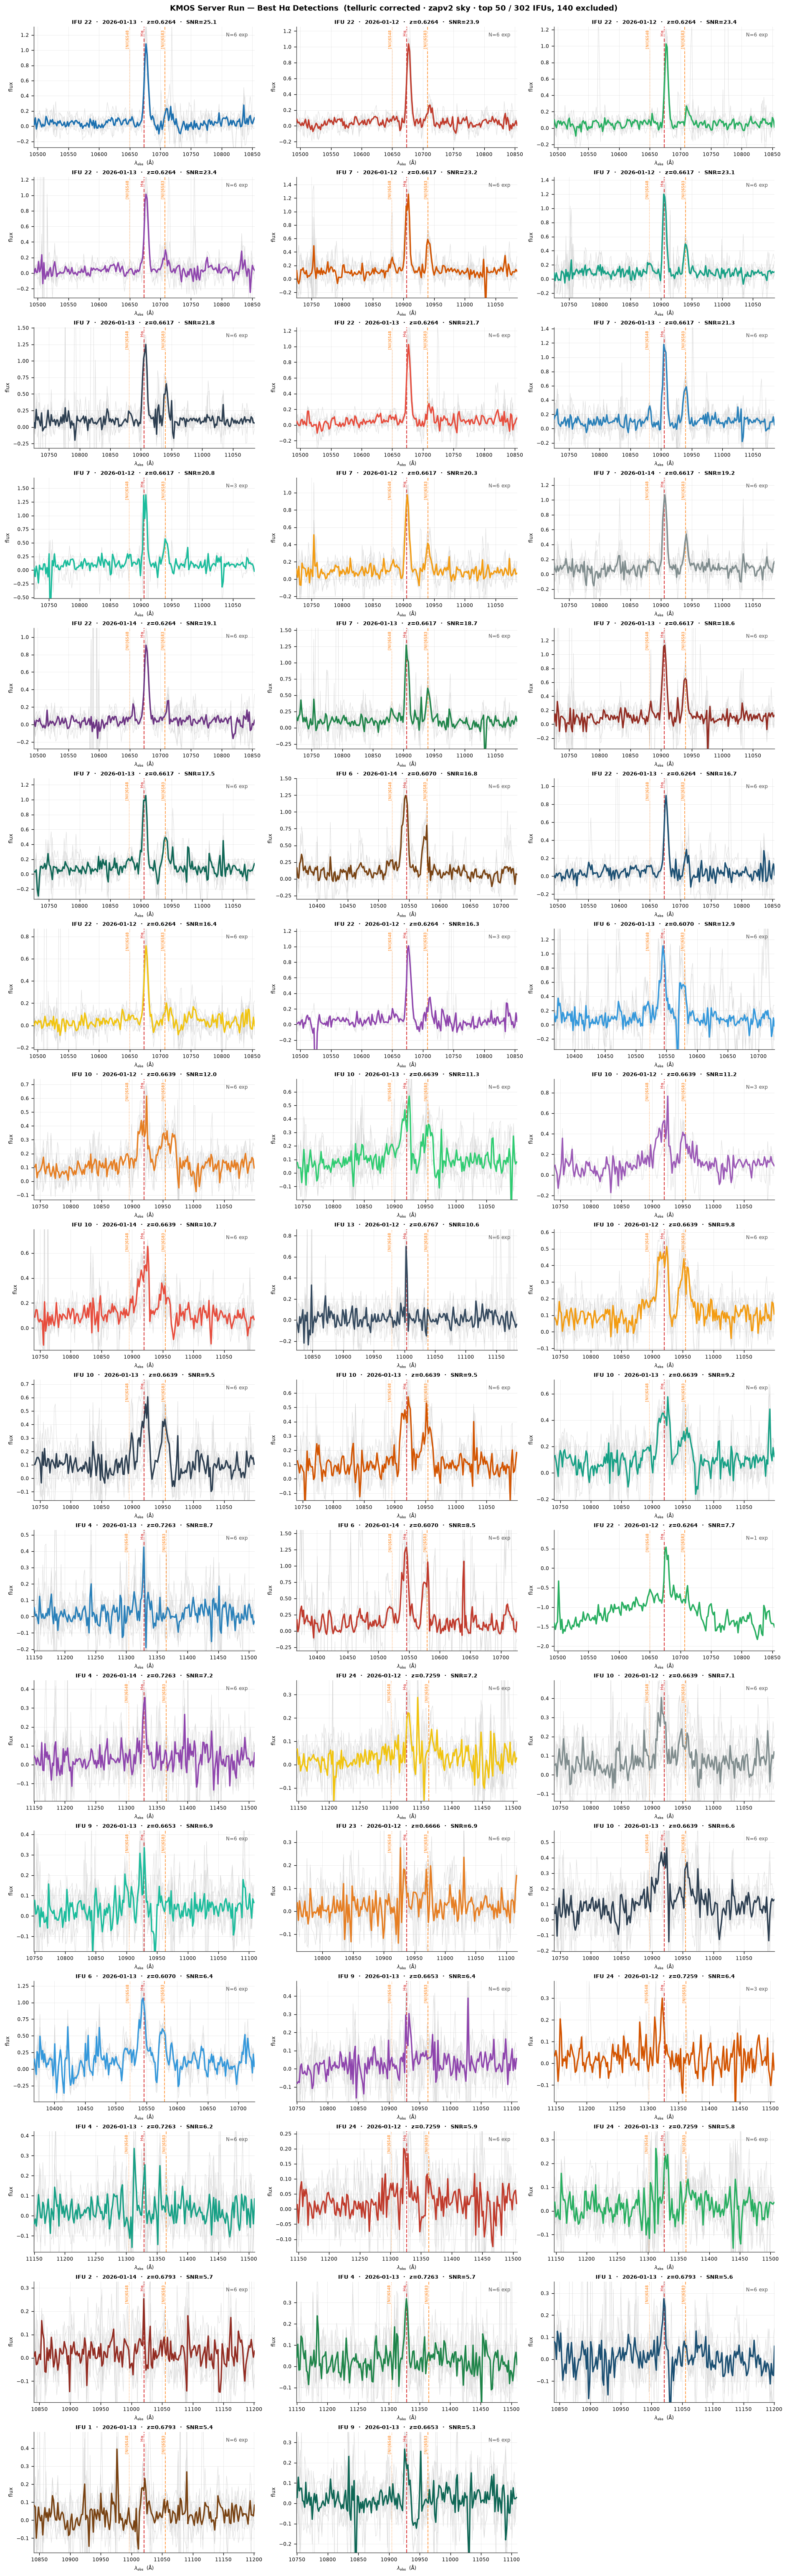

Saved → kmos_showcase_gallery.pdf


In [5]:
top = [
    e for e in all_entries
    if np.isfinite(e.get("snr", np.nan))
    and e["snr"] >= SNR_MIN
    and not e.get("fallback", False)
][:TOP_N]

n_excluded = sum(1 for e in all_entries if e.get("fallback", False))
if n_excluded:
    print(f"Excluded {n_excluded} IFU(s) with offset > {MAX_CENTER_OFFSET} px "
          f"(sky/edge artefact fallback).")

# both [NII] lines to mark in every panel
NII_LINES = {
    "[NII]6548": (0.65480, "#ff7f0e", 0.8, ":"),
    "[NII]6583": (0.65835, "#ff7f0e", 1.1, "--"),
}

if not top:
    print(f"No IFUs with Hα SNR ≥ {SNR_MIN} after exclusions.")
else:
    ncols = 3
    nrows = int(np.ceil(len(top) / ncols))
    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(ncols * 5.2, nrows * 3.0),
                             constrained_layout=True)
    fig.suptitle(
        f"KMOS Server Run — Best Hα Detections  "
        f"(telluric corrected · zapv2 sky · top {len(top)} / {len(all_entries)} IFUs, "
        f"{n_excluded} excluded)",
        fontsize=11, fontweight="bold", y=1.005,
    )
    axes_flat = np.array(axes).ravel()

    for ax_i, (e, color) in enumerate(zip(top, PALETTE)):
        ax   = axes_flat[ax_i]
        wave = e["wave"]
        z    = e["z"]
        ha   = HA_REST * (1.0 + z)
        wlo  = ha - GALLERY_HALF
        whi  = ha + GALLERY_HALF
        mask = (wave >= wlo) & (wave <= whi)

        if not mask.any():
            ax.set_visible(False)
            continue

        for s in e["spectra"]:
            ax.plot(wave[mask] * 1e4, s[mask],
                    color="#d0d0d0", lw=0.55, alpha=0.7, zorder=1)
        ax.plot(wave[mask] * 1e4, e["med"][mask],
                color=color, lw=2.0, zorder=3)

        # Hα marker
        ax.axvline(ha * 1e4, color="#d62728", lw=1.3, ls="--", alpha=0.85, zorder=2)
        ax.text(ha * 1e4, 0.97, "Hα",
                transform=ax.get_xaxis_transform(),
                rotation=90, ha="right", va="top", fontsize=6, color="#d62728",
                bbox=dict(fc="white", ec="none", alpha=0.6, pad=1))

        # both [NII] lines — always, no range check needed (always within ±180 Å of Hα)
        for lname, (lr, lc, lw, ls) in NII_LINES.items():
            lo = lr * (1.0 + z)
            ax.axvline(lo * 1e4, color=lc, lw=lw, ls=ls, alpha=0.75, zorder=2)
            ax.text(lo * 1e4, 0.97, lname,
                    transform=ax.get_xaxis_transform(),
                    rotation=90, ha="right", va="top", fontsize=5.5, color=lc,
                    bbox=dict(fc="white", ec="none", alpha=0.6, pad=1))

        # y-limits: lower from p2 (robust, clips noise spikes), upper from nanmax (shows peak)
        vis = e["med"][mask]
        fv  = vis[np.isfinite(vis)]
        if fv.size:
            ylo = np.nanpercentile(fv, 2)
            yhi = np.nanmax(fv)
            pad = 0.20 * max(yhi - ylo, 0)
            ax.set_ylim(ylo - pad, yhi + pad)

        ax.set_xlim(wlo * 1e4, whi * 1e4)
        ax.set_xlabel(r"$\lambda_{\rm obs}$  (Å)", fontsize=7)
        ax.set_ylabel("flux", fontsize=7)
        ax.tick_params(labelsize=7)
        ax.set_title(
            f"IFU {e['ifu']}  ·  {e['ob_date']}  ·  "
            f"z={z:.4f}  ·  SNR={e['snr']:.1f}",
            pad=4, fontsize=8,
        )
        ax.text(0.97, 0.95, f"N={e['n_exp']} exp",
                transform=ax.transAxes, ha="right", va="top",
                fontsize=7, color="#555")

    for ax in axes_flat[len(top):]:
        ax.set_visible(False)

    plt.savefig("kmos_showcase_gallery.pdf", bbox_inches="tight")
    plt.show()
    print(f"Saved → kmos_showcase_gallery.pdf")

## Detail view — full spectrum + spatial maps

For the best targets: left panel shows the full spectrum with all lines in band
annotated; right panels show the **white-light collapsed** image and the
**H$\alpha$ wavelength slice** (±3 spectral pixels).

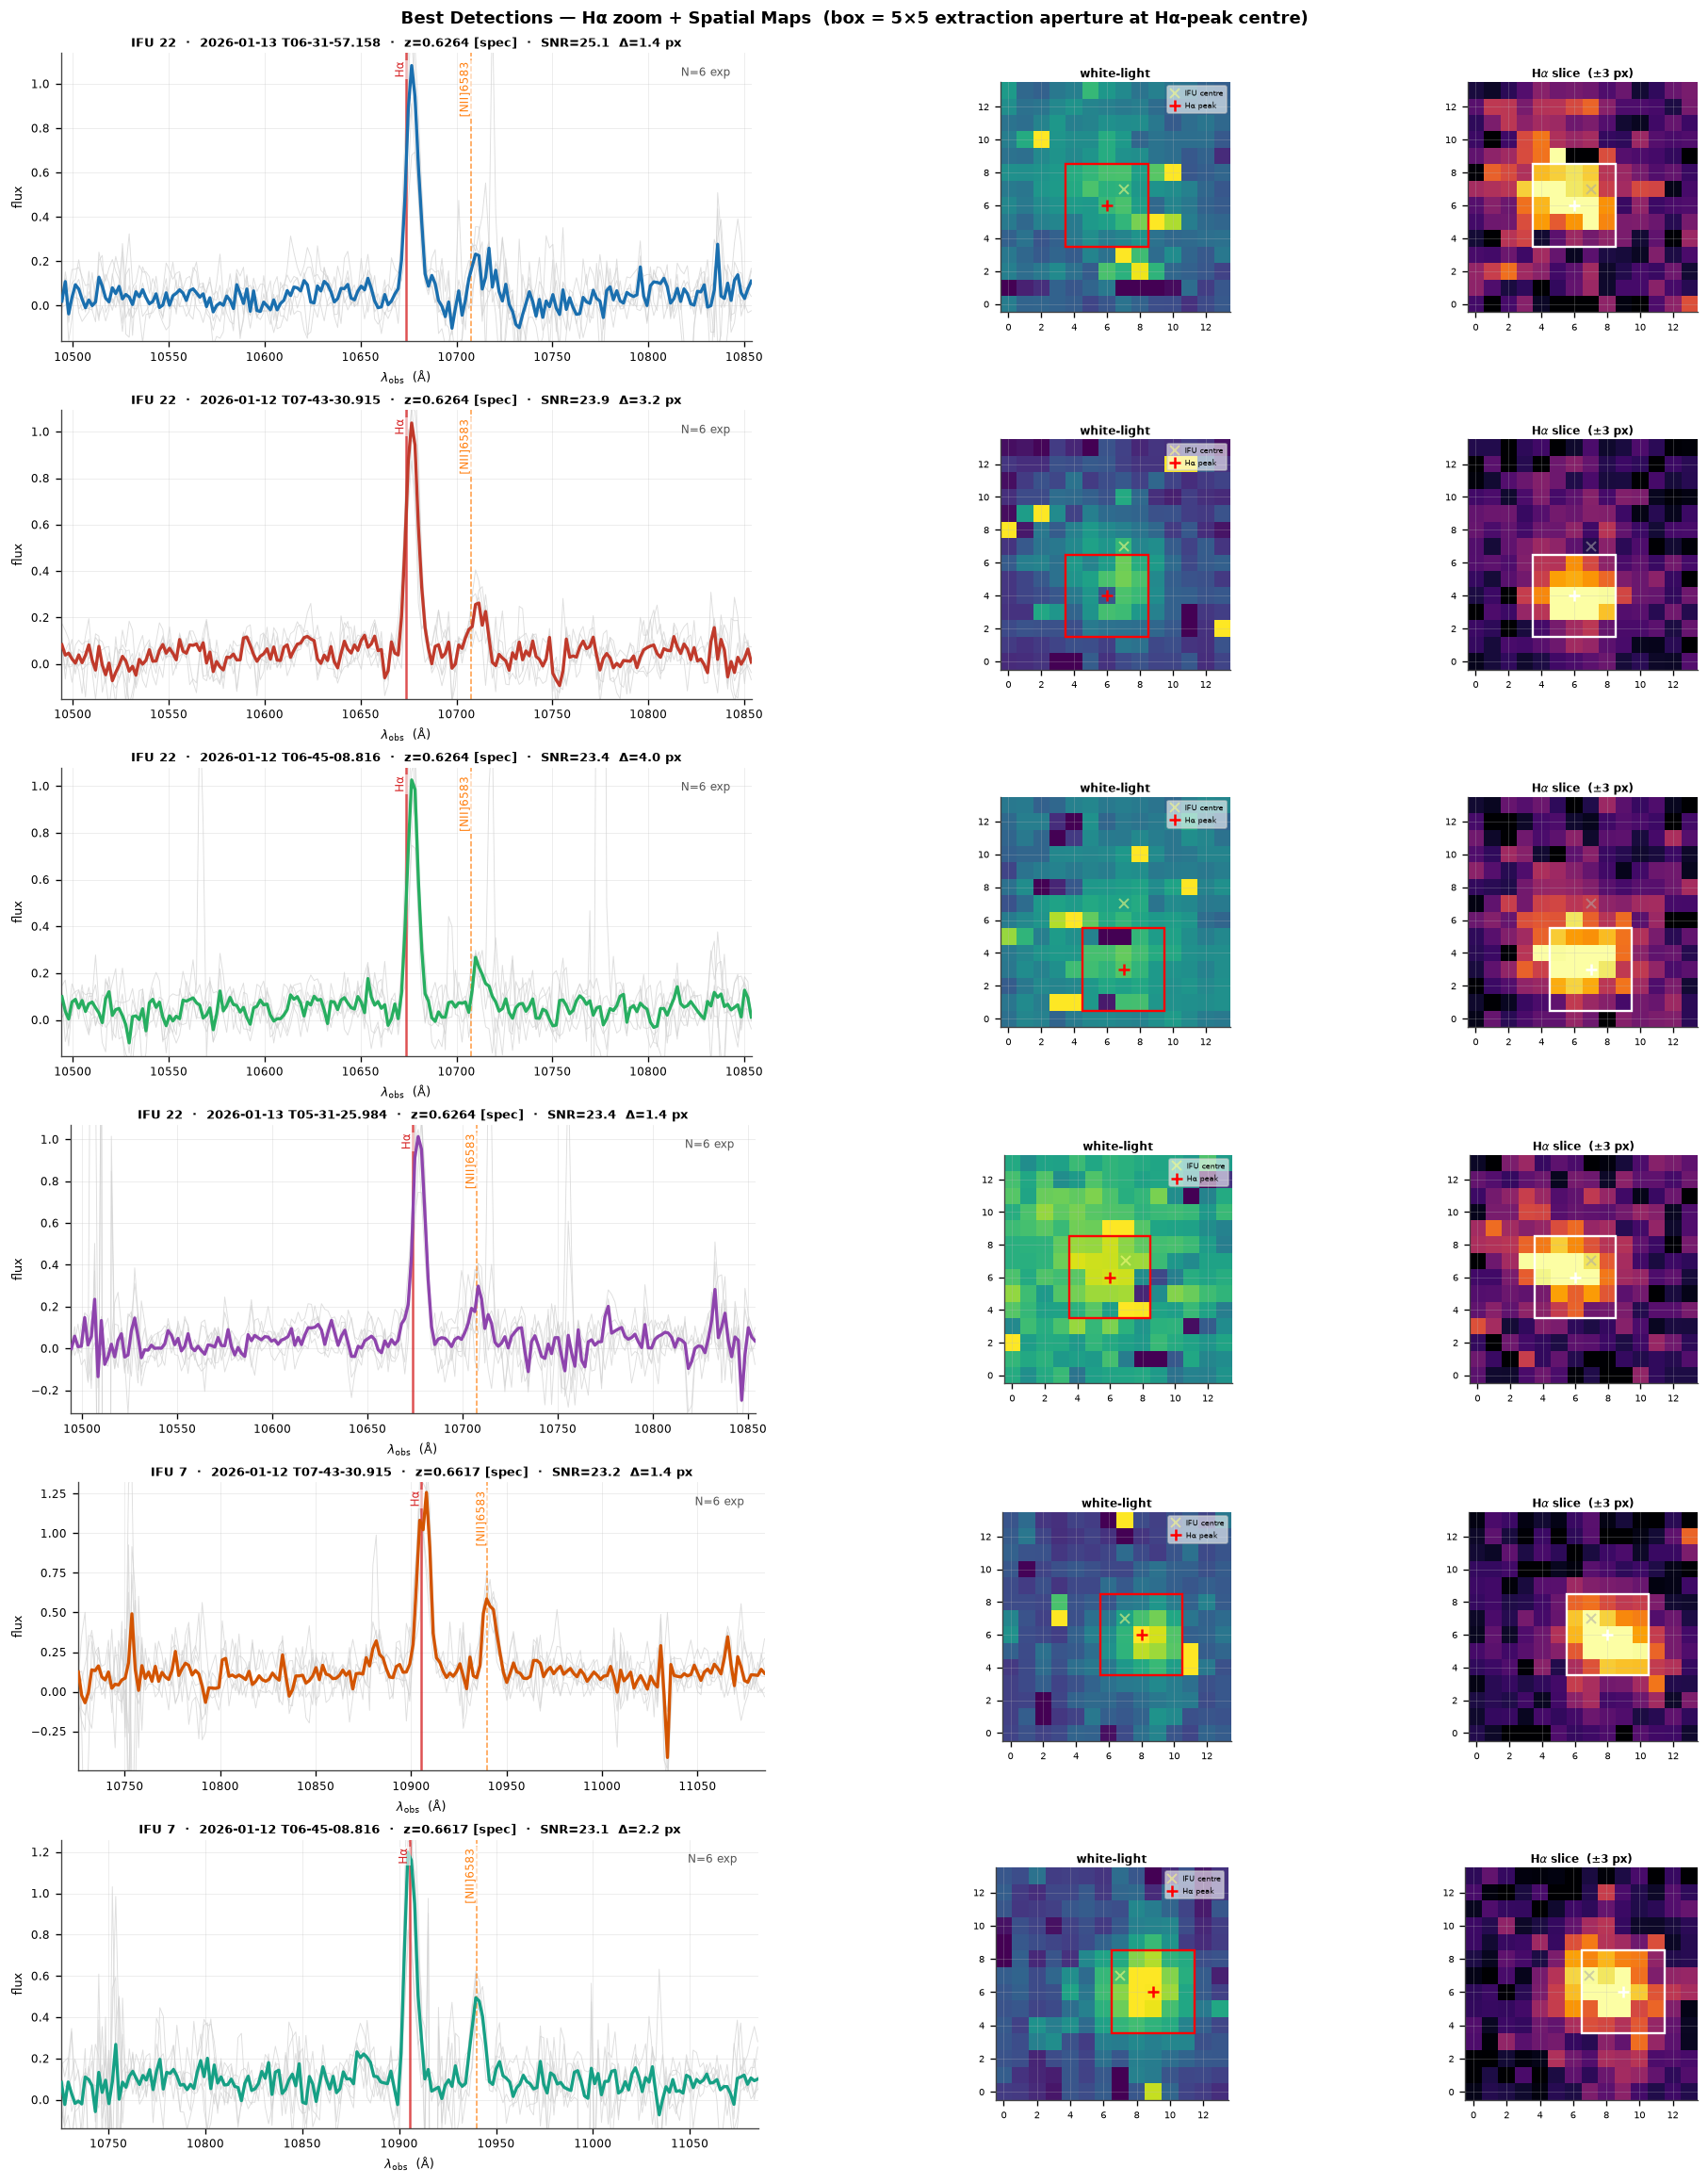

Saved → kmos_showcase_detail.pdf


In [6]:
from matplotlib.patches import Rectangle

n_det = min(TOP_DETAIL, len(top))
if n_det == 0:
    print("No targets to display.")
else:
    fig = plt.figure(figsize=(15, n_det * 3.2), constrained_layout=True)
    fig.suptitle(
        "Best Detections — Hα zoom + Spatial Maps  "
        "(box = 5×5 extraction aperture at Hα-peak centre)",
        fontsize=11, fontweight="bold"
    )
    outer = gridspec.GridSpec(n_det, 1, figure=fig)

    def _apt_rect(cy, cx, box=APERTURE, **kw):
        h2 = box // 2
        return Rectangle((cx - h2 - 0.5, cy - h2 - 0.5), box, box,
                          linewidth=1.4, fill=False, **kw)

    def _annotate_map(ax, cy_ha, cx_ha, cy_geo, cx_geo, moved, ec, lc_geo):
        if moved:
            ax.plot(cx_geo, cy_geo, "x", ms=6, mew=1.2,
                    color=lc_geo, alpha=0.55, zorder=4, label="IFU centre")
        ax.plot(cx_ha, cy_ha, "+", ms=7, mew=1.5,
                color=ec, zorder=5, label="Hα peak")
        ax.add_patch(_apt_rect(cy_ha, cx_ha, edgecolor=ec, zorder=5))

    for row_i, (e, color) in enumerate(zip(top[:n_det], PALETTE)):
        inner = gridspec.GridSpecFromSubplotSpec(
            1, 3, subplot_spec=outer[row_i],
            width_ratios=[3, 1, 1], wspace=0.38
        )
        ax_sp = fig.add_subplot(inner[0])
        ax_wl = fig.add_subplot(inner[1])
        ax_ha = fig.add_subplot(inner[2])

        wave, z        = e["wave"], e["z"]
        ha_obs         = HA_REST * (1.0 + z)
        cy_ha, cx_ha   = e["ctr_ha"]
        cy_geo, cx_geo = e["ctr_geom"]
        moved          = (cy_ha, cx_ha) != (cy_geo, cx_geo)

        # ── Hα zoom spectrum ───────────────────────────────────────────────────
        wlo = ha_obs - GALLERY_HALF
        whi = ha_obs + GALLERY_HALF
        m   = (wave >= wlo) & (wave <= whi)

        for s in e["spectra"]:
            ax_sp.plot(wave[m] * 1e4, s[m],
                       color="#d0d0d0", lw=0.55, alpha=0.7, zorder=1)
        ax_sp.plot(wave[m] * 1e4, e["med"][m], color=color, lw=2.0, zorder=3)

        # Hα and [NII] line markers
        for lname, lr in EMISSION_LINES.items():
            lo = lr * (1.0 + z)
            if wlo <= lo <= whi:
                lc = LINE_COLORS[lname]
                ax_sp.axvline(lo * 1e4, color=lc,
                              lw=1.5 if lname == "Hα" else 0.9,
                              ls="-" if lname == "Hα" else "--",
                              alpha=0.8, zorder=2)
                ax_sp.text(lo * 1e4, 0.97, lname,
                           transform=ax_sp.get_xaxis_transform(),
                           rotation=90, ha="right", va="top", fontsize=7, color=lc,
                           bbox=dict(fc="white", ec="none", alpha=0.6, pad=1))

        ax_sp.set_xlim(wlo * 1e4, whi * 1e4)

        # y-limits from the visible data
        vis = e["med"][m]
        fv  = vis[np.isfinite(vis)]
        if fv.size:
            # Zoom to the data range, excluding error limits/outliers.
            p2, p98 = np.nanpercentile(fv, [2, 100])
            pad = 0.05 * max(p98 - p2, 0)
            ymax = np.nanmax(fv)
            ymin = np.nanmin(fv)
            mini_pad = 0.05 * max(ymax - ymin, 0)
            ax_sp.set_ylim(ymin - mini_pad, ymax + pad)

        off_str = (f"  Δ={e['offset_px']:.1f} px" if moved else "  (centred)")
        fb_str  = "  [fallback to IFU centre]" if e.get("fallback") else ""
        ax_sp.set_title(
            f"IFU {e['ifu']}  ·  {e['ob_date']} T{e['ob_time']}  ·  "
            f"z={z:.4f} [{e['z_type']}]  ·  SNR={e['snr']:.1f}{off_str}{fb_str}",
            fontsize=8, pad=4,
        )
        ax_sp.set_xlabel(r"$\lambda_{\rm obs}$  (Å)", fontsize=8)
        ax_sp.set_ylabel("flux", fontsize=8)
        ax_sp.tick_params(labelsize=7)
        ax_sp.text(0.97, 0.95, f"N={e['n_exp']} exp",
                   transform=ax_sp.transAxes, ha="right", va="top",
                   fontsize=7, color="#555")

        # ── spatial maps ───────────────────────────────────────────────────────
        if e["cube"] is not None:
            cube  = e["cube"]
            valid = _erode_valid(np.isfinite(cube), EDGE_MARGIN)
            wl_im = np.nansum(np.where(valid, cube, np.nan), axis=0)

            ax_wl.imshow(wl_im, origin="lower", aspect="equal", cmap="viridis",
                         vmin=np.nanpercentile(wl_im, 2),
                         vmax=np.nanpercentile(wl_im, 98))
            _annotate_map(ax_wl, cy_ha, cx_ha, cy_geo, cx_geo, moved,
                          ec="red", lc_geo="#ffff80")
            ax_wl.set_title("white-light", fontsize=7, pad=3)
            ax_wl.tick_params(labelsize=6)
            if moved:
                ax_wl.legend(fontsize=5, loc="upper right",
                             framealpha=0.6, handlelength=1)

            # Hα narrow-band
            ha_im = e.get("ha_image")
            if ha_im is None:
                hp = int(np.argmin(np.abs(wave - ha_obs)))
                p0_, p1_ = max(hp - 3, 0), min(hp + 4, cube.shape[0])
                ha_im = np.nansum(
                    np.where(valid[p0_:p1_], cube[p0_:p1_], np.nan), axis=0)

            fin_ha = ha_im[np.isfinite(ha_im)]
            if fin_ha.size:
                ax_ha.imshow(ha_im, origin="lower", aspect="equal", cmap="inferno",
                             vmin=np.nanpercentile(fin_ha, 5),
                             vmax=np.nanpercentile(fin_ha, 97))
                _annotate_map(ax_ha, cy_ha, cx_ha, cy_geo, cx_geo, moved,
                              ec="white", lc_geo="#aaaaaa")
                ax_ha.set_title(r"H$\alpha$ slice  (±3 px)", fontsize=7, pad=3)
                ax_ha.tick_params(labelsize=6)
            else:
                ax_ha.set_visible(False)
        else:
            ax_wl.set_visible(False)
            ax_ha.set_visible(False)

    plt.savefig("kmos_showcase_detail.pdf", bbox_inches="tight")
    plt.show()
    print("Saved → kmos_showcase_detail.pdf")

In [7]:
# ── generalized line-analysis helpers ─────────────────────────────────────────
def line_snr(wave, spec, z, line_rest,
             win_half=SNR_WIN_HALF, cont_in=SNR_CONT_IN, cont_out=SNR_CONT_OUT):
    """Continuum-subtracted peak SNR for any emission line (MAD noise)."""
    lam = line_rest * (1.0 + z)
    if not (wave.min() < lam < wave.max()):
        return np.nan
    sig_mask  = np.abs(wave - lam) <= win_half
    cont_mask = (np.abs(wave - lam) >= cont_in) & (np.abs(wave - lam) <= cont_out)
    if sig_mask.sum() < 1 or cont_mask.sum() < 8:
        return np.nan
    wc, sc = wave[cont_mask], spec[cont_mask]
    ok = np.isfinite(sc)
    if ok.sum() < 4:
        return np.nan
    p         = np.polyfit(wc[ok], sc[ok], 1)
    cont_line = np.polyval(p, wave)
    peak      = np.nanmax(spec[sig_mask] - cont_line[sig_mask])
    cs_cont   = (spec[cont_mask] - cont_line[cont_mask])[np.isfinite(spec[cont_mask])]
    if cs_cont.size < 4:
        return np.nan
    mad   = np.nanmedian(np.abs(cs_cont - np.nanmedian(cs_cont)))
    noise = 1.4826 * mad
    if noise <= 0 or not np.isfinite(noise):
        return np.nan
    return float(peak / noise)


def line_peak_center(cube, wave, z, line_rest, margin=EDGE_MARGIN, min_nbr=0.08):
    """Peak spaxel in a ±3-pixel narrow-band image around any emission line."""
    lam_obs = line_rest * (1.0 + z)
    if not (wave.min() < lam_obs < wave.max()):
        return ifu_center(cube), None
    hp      = int(np.argmin(np.abs(wave - lam_obs)))
    p0, p1  = max(hp - 3, 0), min(hp + 4, cube.shape[0])
    valid   = _erode_valid(np.isfinite(cube[p0:p1]), margin)
    nb_im   = np.nansum(np.where(valid, cube[p0:p1], np.nan), axis=0)
    ny, nx  = nb_im.shape
    flat    = nb_im.ravel()
    order   = np.argsort(np.where(np.isfinite(flat), flat, -np.inf))[::-1]
    for idx in order:
        v = flat[idx]
        if not np.isfinite(v) or v <= 0:
            break
        py, px = np.unravel_index(idx, (ny, nx))
        nbrs = [nb_im[py+dy, px+dx]
                for dy in (-1, 0, 1) for dx in (-1, 0, 1)
                if (dy, dx) != (0, 0) and 0 <= py+dy < ny and 0 <= px+dx < nx]
        nbrs = [n for n in nbrs if np.isfinite(n)]
        if nbrs and np.mean(nbrs) >= min_nbr * v:
            return (py, px), nb_im
    return ifu_center(cube), nb_im

## [OIII]λ5007 detections

Same ranking and visualisation as the Hα section, now centred on
**[OIII]λ5007**.  For galaxies at z ≈ 0.6–0.8, [OIII]5007 falls in the
**IZ band** (~0.83 µm), so only IFUs with IZ-band coverage yield a finite SNR
here.  The companion [OIII]λ4959 and Hβ lines are marked where they fall in
the window.

In [8]:
# ── [OIII]λ5007  ranking ─────────────────────────────────────────────────────
OIII_REST  = 0.50082   # µm — [OIII]λ5007
OIII_HALF  = 0.018     # ±µm gallery window
OIII_COLOR = "#17becf"
OIII_COMP  = {
    "[OIII]4959": (0.49594, "#7fdbff", 0.9, ":"),
    "Hβ":         (0.48627, "#1f77b4", 0.9, "--"),
}

print("Scoring [OIII]λ5007 on all IFUs …")
for e in all_entries:
    e["oiii_snr"] = line_snr(e["wave"], e["med"], e["z"], OIII_REST)
    if e["cube"] is not None:
        ctr_raw, nb_im = line_peak_center(e["cube"], e["wave"], e["z"], OIII_REST)
        offset = np.hypot(ctr_raw[0] - e["ctr_geom"][0],
                          ctr_raw[1] - e["ctr_geom"][1])
        e["oiii_ctr"]      = ctr_raw if offset <= MAX_CENTER_OFFSET else e["ctr_geom"]
        e["oiii_image"]    = nb_im
        e["oiii_fallback"] = offset > MAX_CENTER_OFFSET
    else:
        e["oiii_ctr"] = e["ctr_geom"]; e["oiii_image"] = None; e["oiii_fallback"] = False

oiii_ranked = sorted(
    [e for e in all_entries if np.isfinite(e.get("oiii_snr", np.nan))],
    key=lambda x: x["oiii_snr"], reverse=True
)
n_oiii = sum(1 for e in oiii_ranked if e["oiii_snr"] >= SNR_MIN)
print(f"[OIII]5007 detections (SNR ≥ {SNR_MIN}): {n_oiii} / {len(oiii_ranked)} IFUs in range\n")
print(f"{'Rank':>4}  {'OB date':12s}  {'IFU':>4}  {'z':>7}  {'type':>5}  "
      f"{'[OIII] SNR':>10}  {'Hα SNR':>8}")
print("-" * 72)
for i, e in enumerate(oiii_ranked[:20]):
    ha_s = f"{e['snr']:.1f}" if np.isfinite(e.get("snr", np.nan)) else "—"
    print(f"{i+1:>4}  {e['ob_date']:12s}  {e['ifu']:>4}  {e['z']:>7.4f}  "
          f"{e['z_type']:>5}  {e['oiii_snr']:>10.1f}  {ha_s:>8}")

Scoring [OIII]λ5007 on all IFUs …
[OIII]5007 detections (SNR ≥ 2.0): 35 / 60 IFUs in range

Rank  OB date        IFU        z   type  [OIII] SNR    Hα SNR
------------------------------------------------------------------------
   1  2026-01-14       3   0.7330   spec        14.9         —
   2  2026-01-14       3   0.7330   spec        11.8         —
   3  2026-01-14       6   0.6070   spec         8.3       8.5
   4  2026-01-13       7   0.6070   spec         6.6       1.5
   5  2026-01-14       6   0.6070   spec         6.0      16.8
   6  2026-01-14      11   0.6760   spec         5.9         —
   7  2026-01-13      11   0.6760   spec         5.5         —
   8  2026-01-14       7   0.6070   spec         5.4       2.0
   9  2026-01-14       5   0.6480   spec         5.0       2.7
  10  2026-01-14      16   0.7620  photo         4.9         —
  11  2026-01-13       6   0.6070   spec         4.7       6.4
  12  2026-01-14       9   0.8140  photo         4.6         —
  13  2026-01-13

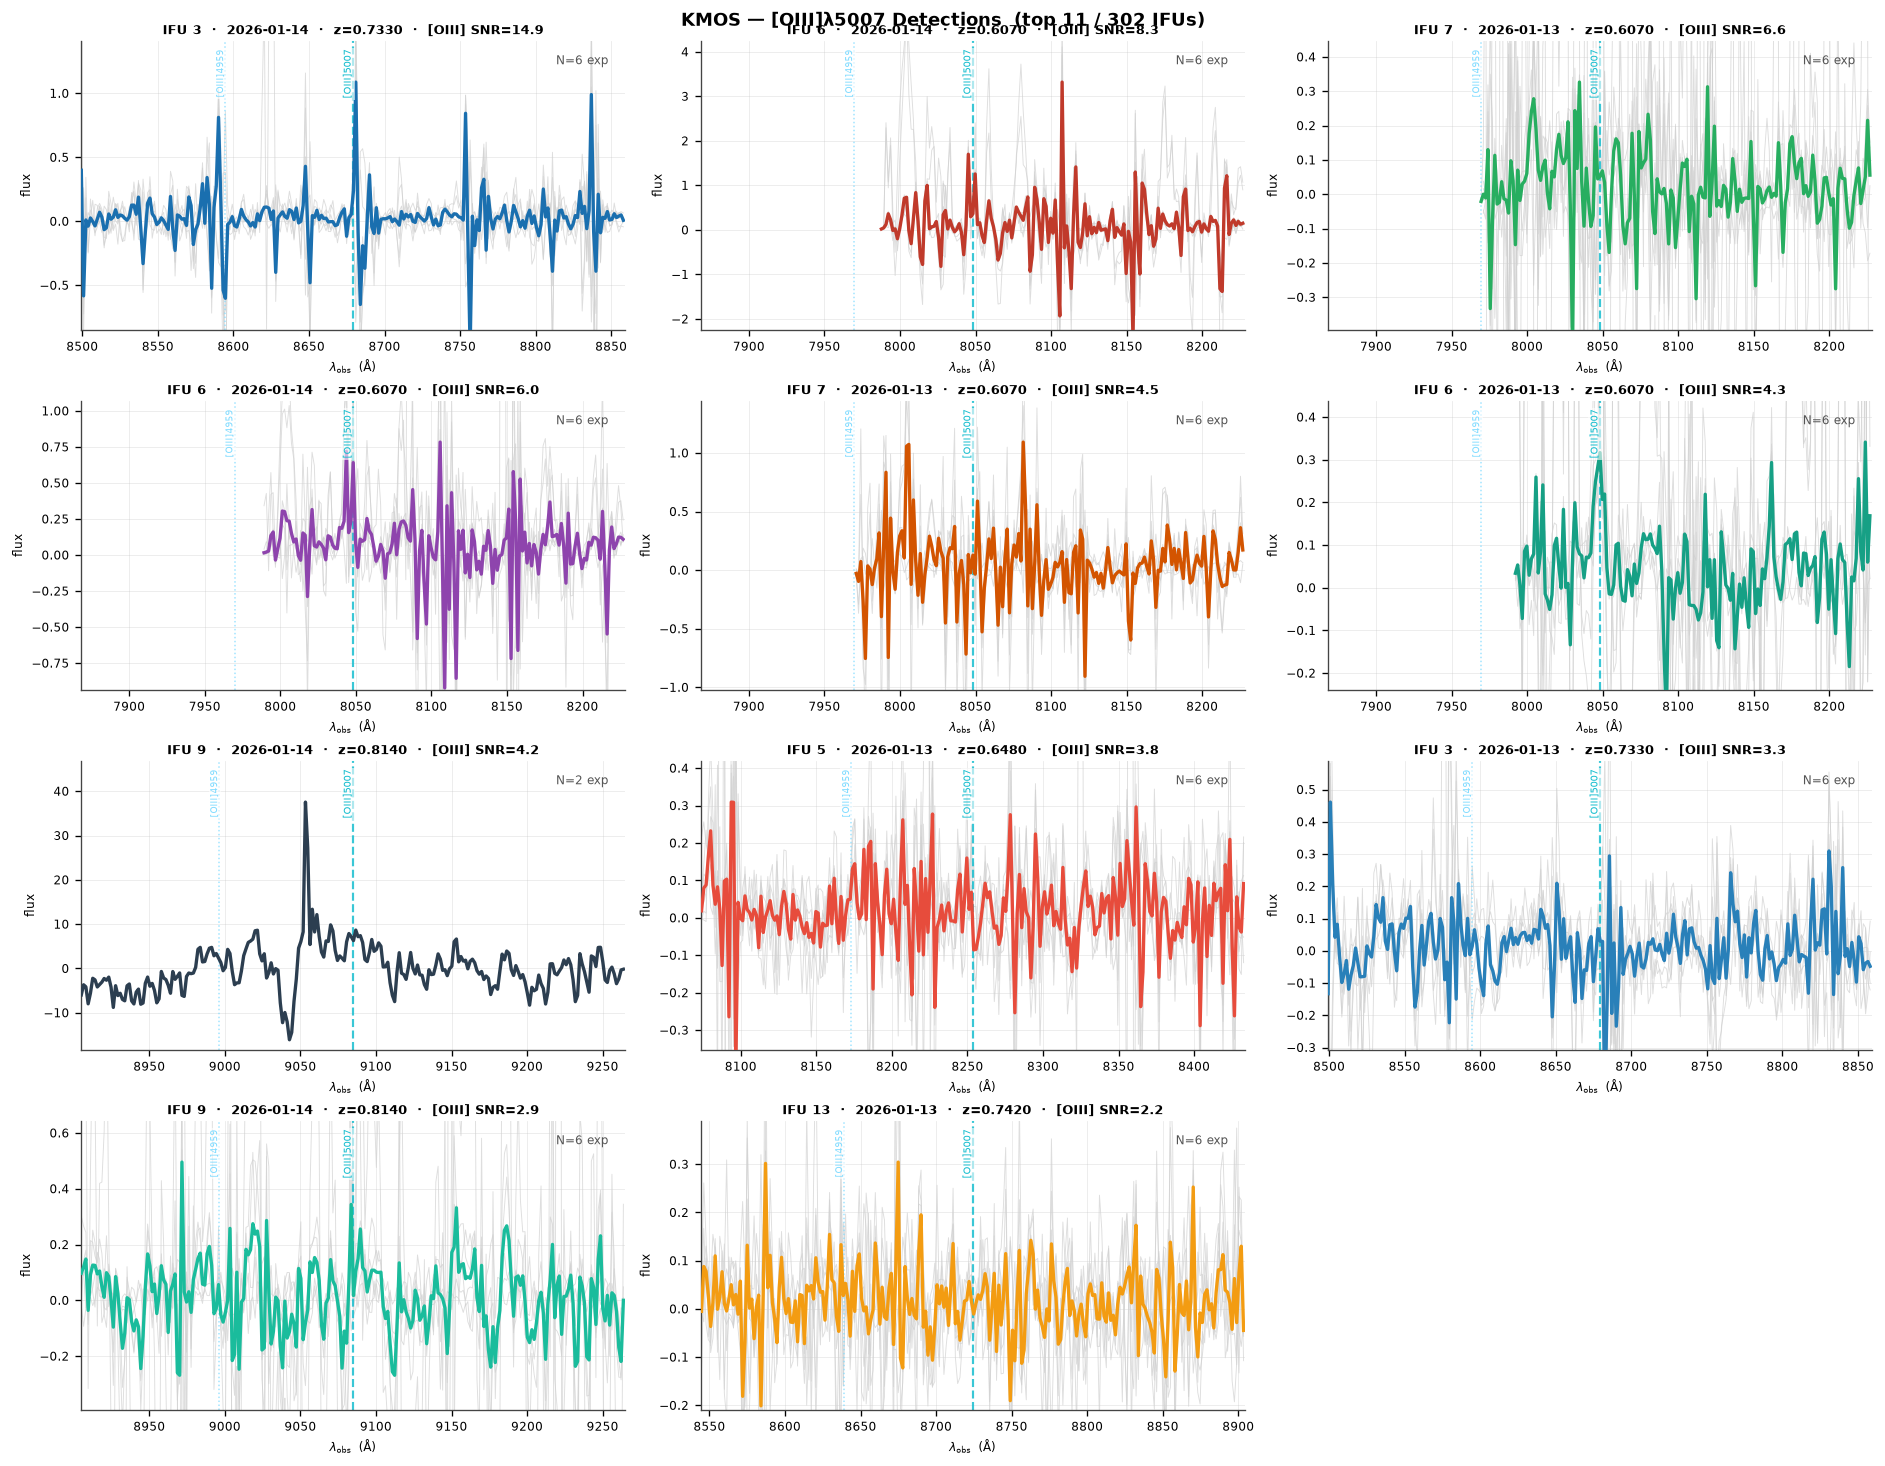

Saved → kmos_showcase_oiii_gallery.pdf


In [9]:
# ── [OIII]λ5007  gallery ──────────────────────────────────────────────────────
top_oiii = [
    e for e in oiii_ranked
    if e["oiii_snr"] >= SNR_MIN and not e.get("oiii_fallback", False)
][:TOP_N]

if not top_oiii:
    print(f"No [OIII]5007 detections with SNR ≥ {SNR_MIN}.")
else:
    ncols = 3
    nrows = int(np.ceil(len(top_oiii) / ncols))
    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(ncols * 5.2, nrows * 3.0),
                             constrained_layout=True)
    fig.suptitle(
        f"KMOS — [OIII]λ5007 Detections  (top {len(top_oiii)} / {len(all_entries)} IFUs)",
        fontsize=11, fontweight="bold", y=1.005,
    )
    axes_flat = np.array(axes).ravel()

    for ax_i, (e, color) in enumerate(zip(top_oiii, PALETTE)):
        ax   = axes_flat[ax_i]
        wave = e["wave"]
        z    = e["z"]
        lam  = OIII_REST * (1.0 + z)
        wlo  = lam - OIII_HALF
        whi  = lam + OIII_HALF
        mask = (wave >= wlo) & (wave <= whi)
        if not mask.any():
            ax.set_visible(False); continue

        for s in e["spectra"]:
            ax.plot(wave[mask] * 1e4, s[mask],
                    color="#d0d0d0", lw=0.55, alpha=0.7, zorder=1)
        ax.plot(wave[mask] * 1e4, e["med"][mask], color=color, lw=2.0, zorder=3)

        ax.axvline(lam * 1e4, color=OIII_COLOR, lw=1.3, ls="--", alpha=0.85, zorder=2)
        ax.text(lam * 1e4, 0.97, "[OIII]5007",
                transform=ax.get_xaxis_transform(),
                rotation=90, ha="right", va="top", fontsize=6, color=OIII_COLOR,
                bbox=dict(fc="white", ec="none", alpha=0.6, pad=1))
        for lname, (lr, lc, lw_, ls) in OIII_COMP.items():
            lo = lr * (1.0 + z)
            if wlo <= lo <= whi:
                ax.axvline(lo * 1e4, color=lc, lw=lw_, ls=ls, alpha=0.75, zorder=2)
                ax.text(lo * 1e4, 0.97, lname,
                        transform=ax.get_xaxis_transform(),
                        rotation=90, ha="right", va="top", fontsize=5.5, color=lc,
                        bbox=dict(fc="white", ec="none", alpha=0.6, pad=1))

        vis = e["med"][mask]
        fv  = vis[np.isfinite(vis)]
        if fv.size:
            ylo = np.nanpercentile(fv, 2); yhi = np.nanmax(fv)
            pad = 0.20 * max(yhi - ylo, 0)
            ax.set_ylim(ylo - pad, yhi + pad)

        ax.set_xlim(wlo * 1e4, whi * 1e4)
        ax.set_xlabel(r"$\lambda_{\rm obs}$  (Å)", fontsize=7)
        ax.set_ylabel("flux", fontsize=7)
        ax.tick_params(labelsize=7)
        ax.set_title(
            f"IFU {e['ifu']}  ·  {e['ob_date']}  ·  z={z:.4f}  ·  "
            f"[OIII] SNR={e['oiii_snr']:.1f}",
            pad=4, fontsize=8)
        ax.text(0.97, 0.95, f"N={e['n_exp']} exp",
                transform=ax.transAxes, ha="right", va="top", fontsize=7, color="#555")

    for ax in axes_flat[len(top_oiii):]:
        ax.set_visible(False)
    plt.savefig("kmos_showcase_oiii_gallery.pdf", bbox_inches="tight")
    plt.show()
    print("Saved → kmos_showcase_oiii_gallery.pdf")

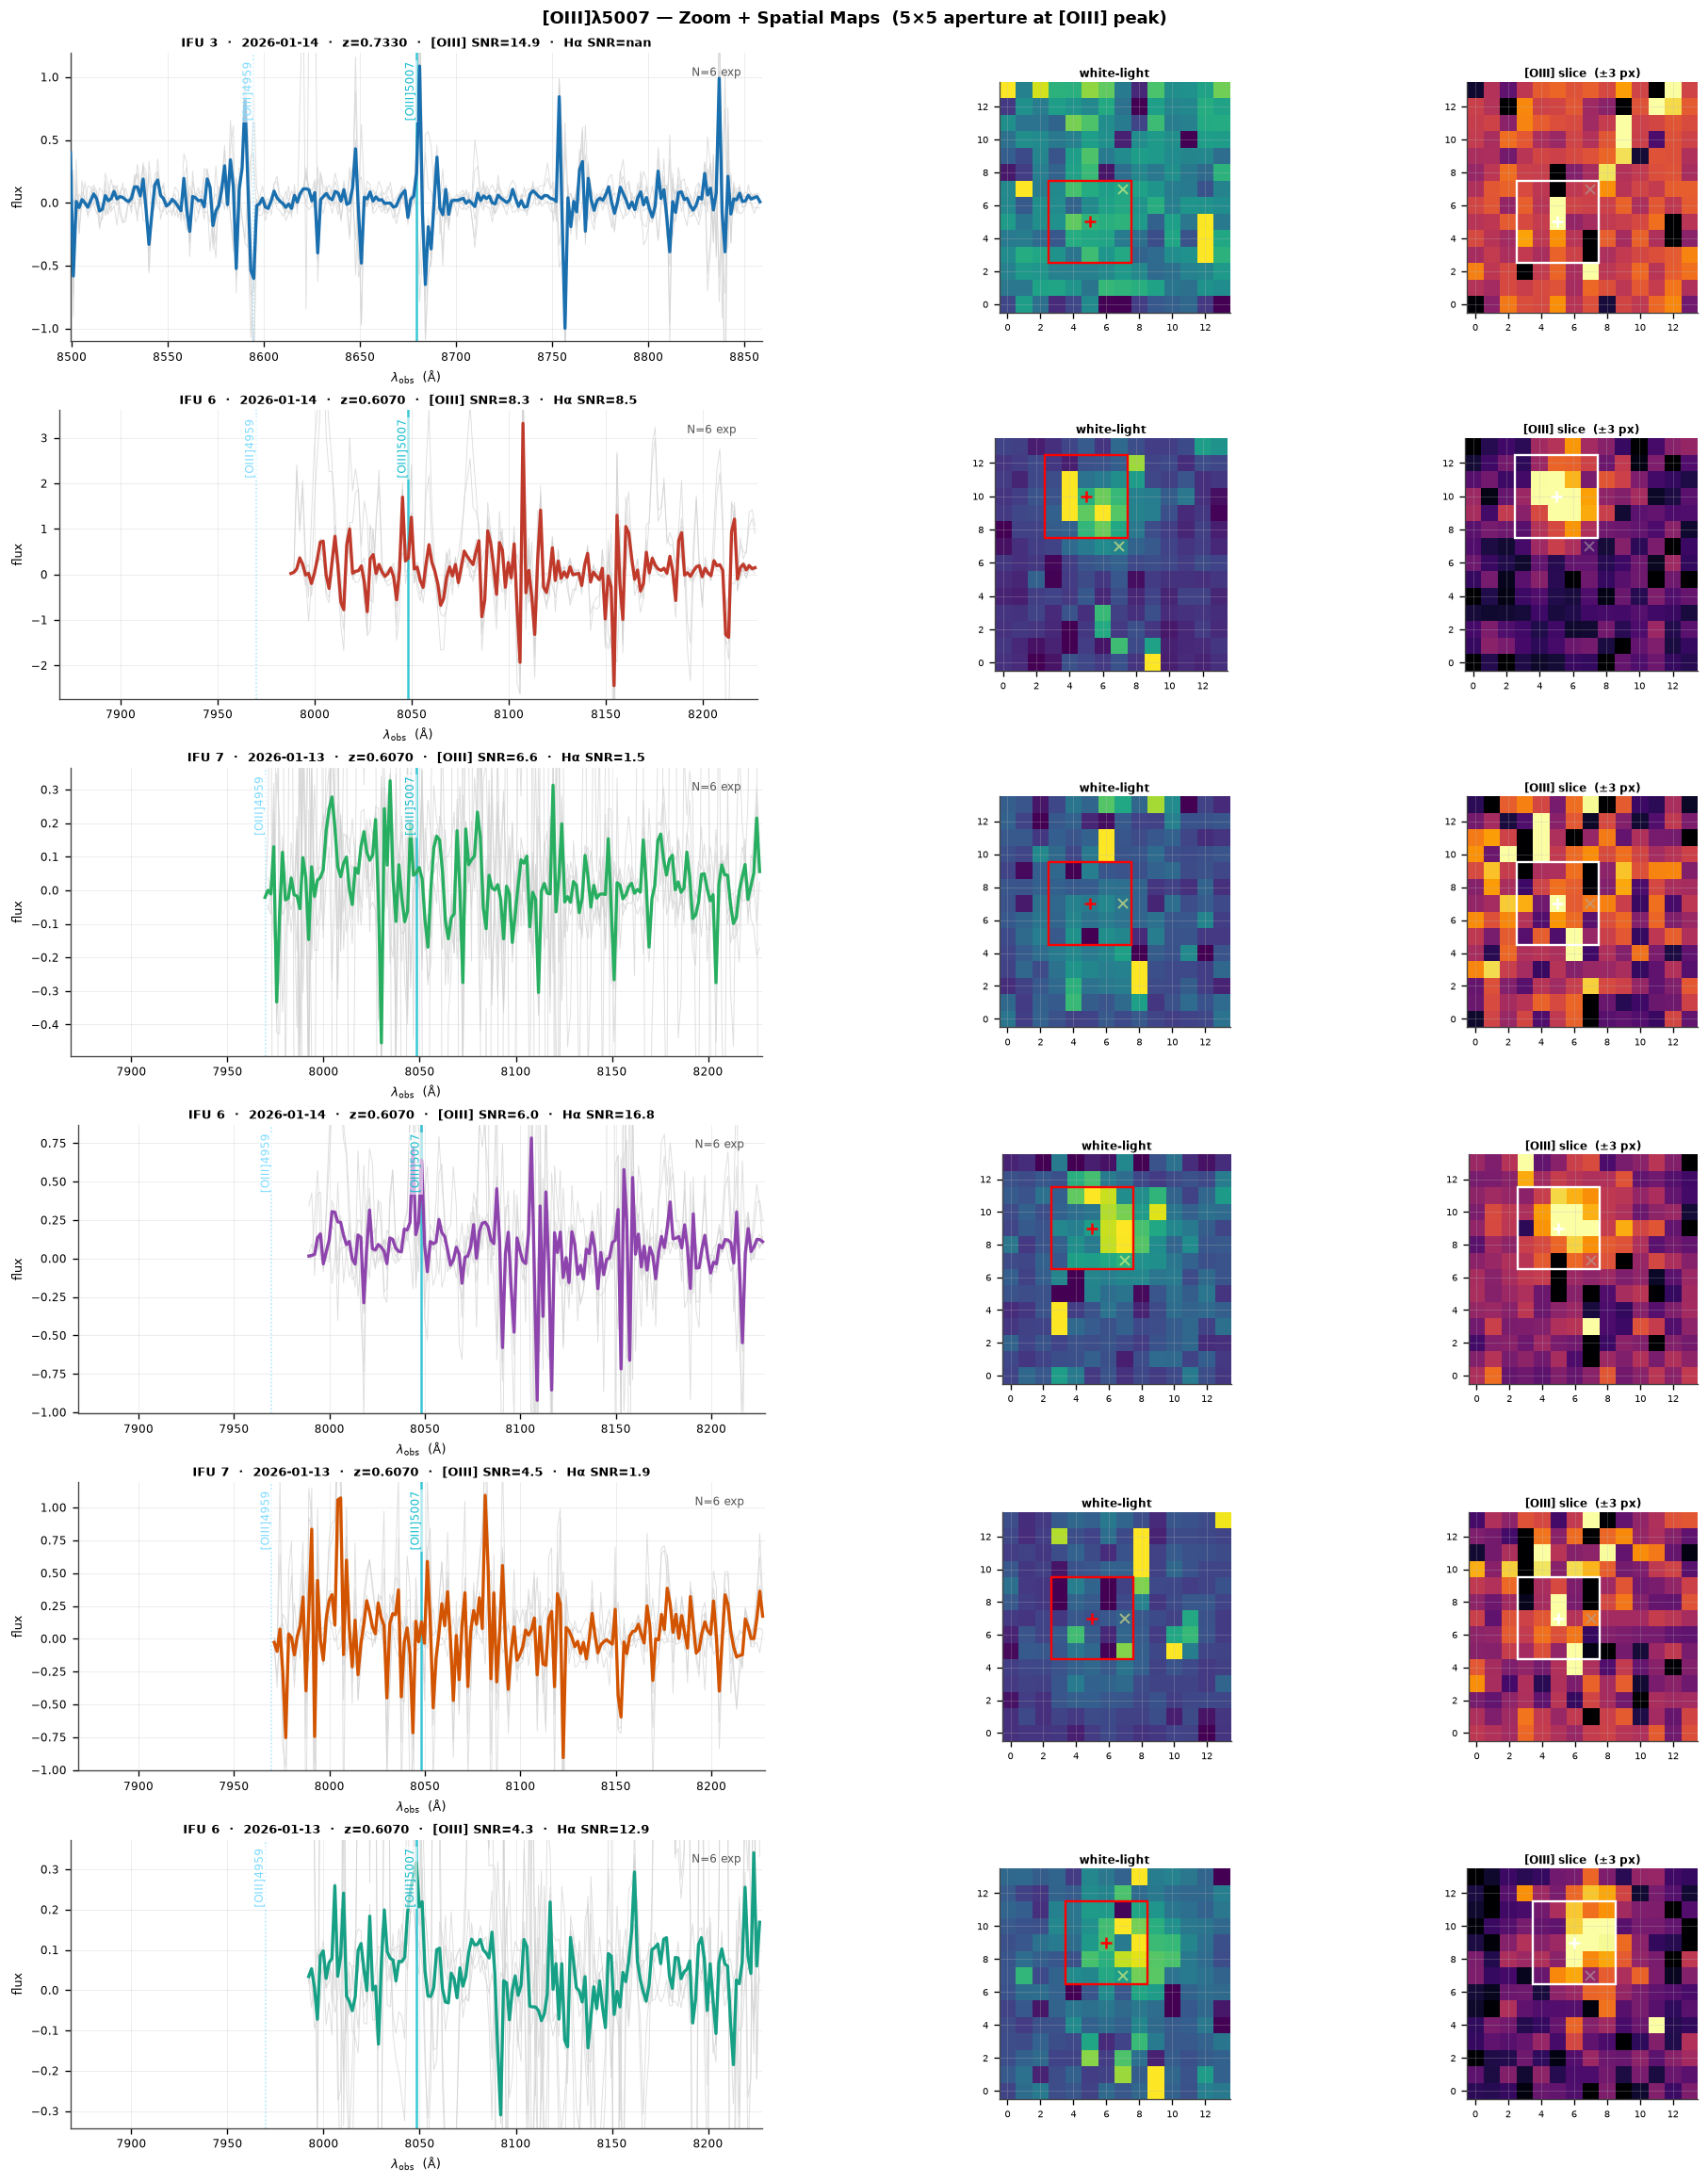

Saved → kmos_showcase_oiii_detail.pdf


In [10]:
# ── [OIII]λ5007  detail view ─────────────────────────────────────────────────
n_det = min(TOP_DETAIL, len(top_oiii))
if n_det == 0:
    print("No [OIII] targets to display.")
else:
    fig = plt.figure(figsize=(15, n_det * 3.2), constrained_layout=True)
    fig.suptitle("[OIII]λ5007 — Zoom + Spatial Maps  (5×5 aperture at [OIII] peak)",
                 fontsize=11, fontweight="bold")
    outer = gridspec.GridSpec(n_det, 1, figure=fig)

    for row_i, (e, color) in enumerate(zip(top_oiii[:n_det], PALETTE)):
        inner = gridspec.GridSpecFromSubplotSpec(
            1, 3, subplot_spec=outer[row_i], width_ratios=[3, 1, 1], wspace=0.38)
        ax_sp = fig.add_subplot(inner[0])
        ax_wl = fig.add_subplot(inner[1])
        ax_nb = fig.add_subplot(inner[2])

        wave, z = e["wave"], e["z"]
        lam     = OIII_REST * (1.0 + z)
        cy, cx  = e["oiii_ctr"]
        cy_geo, cx_geo = e["ctr_geom"]
        moved   = (cy, cx) != (cy_geo, cx_geo)

        wlo, whi = lam - OIII_HALF, lam + OIII_HALF
        m = (wave >= wlo) & (wave <= whi)

        for s in e["spectra"]:
            ax_sp.plot(wave[m] * 1e4, s[m],
                       color="#d0d0d0", lw=0.55, alpha=0.7, zorder=1)
        ax_sp.plot(wave[m] * 1e4, e["med"][m], color=color, lw=2.0, zorder=3)

        ax_sp.axvline(lam * 1e4, color=OIII_COLOR, lw=1.5, ls="-", alpha=0.85, zorder=2)
        ax_sp.text(lam * 1e4, 0.97, "[OIII]5007",
                   transform=ax_sp.get_xaxis_transform(),
                   rotation=90, ha="right", va="top", fontsize=7, color=OIII_COLOR,
                   bbox=dict(fc="white", ec="none", alpha=0.6, pad=1))
        for lname, (lr, lc, lw_, ls) in OIII_COMP.items():
            lo = lr * (1.0 + z)
            if wlo <= lo <= whi:
                ax_sp.axvline(lo * 1e4, color=lc, lw=lw_, ls=ls, alpha=0.75, zorder=2)
                ax_sp.text(lo * 1e4, 0.97, lname,
                           transform=ax_sp.get_xaxis_transform(),
                           rotation=90, ha="right", va="top", fontsize=7, color=lc,
                           bbox=dict(fc="white", ec="none", alpha=0.6, pad=1))

        ax_sp.set_xlim(wlo * 1e4, whi * 1e4)
        vis = e["med"][m]; fv = vis[np.isfinite(vis)]
        if fv.size:
            ymin, ymax = np.nanmin(fv), np.nanmax(fv)
            pad = 0.05 * max(ymax - ymin, 0)
            ax_sp.set_ylim(ymin - pad, ymax + pad)
        ax_sp.set_title(
            f"IFU {e['ifu']}  ·  {e['ob_date']}  ·  z={z:.4f}  ·  "
            f"[OIII] SNR={e['oiii_snr']:.1f}  ·  Hα SNR={e['snr']:.1f}",
            fontsize=8, pad=4)
        ax_sp.set_xlabel(r"$\lambda_{\rm obs}$  (Å)", fontsize=8)
        ax_sp.set_ylabel("flux", fontsize=8)
        ax_sp.tick_params(labelsize=7)
        ax_sp.text(0.97, 0.95, f"N={e['n_exp']} exp",
                   transform=ax_sp.transAxes, ha="right", va="top",
                   fontsize=7, color="#555")

        if e["cube"] is not None:
            cube  = e["cube"]
            valid = _erode_valid(np.isfinite(cube), EDGE_MARGIN)
            wl_im = np.nansum(np.where(valid, cube, np.nan), axis=0)
            ax_wl.imshow(wl_im, origin="lower", aspect="equal", cmap="viridis",
                         vmin=np.nanpercentile(wl_im, 2), vmax=np.nanpercentile(wl_im, 98))
            _annotate_map(ax_wl, cy, cx, cy_geo, cx_geo, moved, ec="red", lc_geo="#ffff80")
            ax_wl.set_title("white-light", fontsize=7, pad=3)
            ax_wl.tick_params(labelsize=6)

            nb_im = e.get("oiii_image")
            if nb_im is not None and nb_im[np.isfinite(nb_im)].size:
                fin = nb_im[np.isfinite(nb_im)]
                ax_nb.imshow(nb_im, origin="lower", aspect="equal", cmap="inferno",
                             vmin=np.nanpercentile(fin, 5), vmax=np.nanpercentile(fin, 97))
                _annotate_map(ax_nb, cy, cx, cy_geo, cx_geo, moved, ec="white", lc_geo="#aaaaaa")
                ax_nb.set_title(r"[OIII] slice  (±3 px)", fontsize=7, pad=3)
                ax_nb.tick_params(labelsize=6)
            else:
                ax_nb.set_visible(False)
        else:
            ax_wl.set_visible(False); ax_nb.set_visible(False)

    plt.savefig("kmos_showcase_oiii_detail.pdf", bbox_inches="tight")
    plt.show()
    print("Saved → kmos_showcase_oiii_detail.pdf")

## [SII]λλ6716,6731 detections

Same ranking and visualisation as the Hα section, centred on **[SII]λ6716**
(the stronger line of the sulphur doublet).  At z ≈ 0.6–0.8 both [SII] lines
**and** Hα fall in the YJ band, so the ±0.018 µm gallery window captures all
three simultaneously.  Hα and [NII]λ6583 are marked in each panel.

In [11]:
# ── [SII]λλ6716,6731  ranking ─────────────────────────────────────────────────
SII_REST  = 0.67163   # µm — [SII]λ6716 (primary, stronger line)
SII_HALF  = 0.018     # ±µm gallery window (same as Hα; captures Hα + both [SII])
SII_COLOR = "#9467bd"
SII_COMP  = {                              # companions shown in gallery window
    "Hα":        (HA_REST,  "#d62728", 1.2, "--"),
    "[NII]6583": (0.65835,  "#ff7f0e", 0.9, ":"),
    "[SII]6731": (0.67308,  "#c5b0d8", 0.9, ":"),
}

print("Scoring [SII]λ6716 on all IFUs …")
for e in all_entries:
    e["sii_snr"] = line_snr(e["wave"], e["med"], e["z"], SII_REST)
    if e["cube"] is not None:
        ctr_raw, nb_im = line_peak_center(e["cube"], e["wave"], e["z"], SII_REST)
        offset = np.hypot(ctr_raw[0] - e["ctr_geom"][0],
                          ctr_raw[1] - e["ctr_geom"][1])
        e["sii_ctr"]      = ctr_raw if offset <= MAX_CENTER_OFFSET else e["ctr_geom"]
        e["sii_image"]    = nb_im
        e["sii_fallback"] = offset > MAX_CENTER_OFFSET
    else:
        e["sii_ctr"] = e["ctr_geom"]; e["sii_image"] = None; e["sii_fallback"] = False

sii_ranked = sorted(
    [e for e in all_entries if np.isfinite(e.get("sii_snr", np.nan))],
    key=lambda x: x["sii_snr"], reverse=True
)
n_sii = sum(1 for e in sii_ranked if e["sii_snr"] >= SNR_MIN)
print(f"[SII]6716 detections (SNR ≥ {SNR_MIN}): {n_sii} / {len(sii_ranked)} IFUs in range\n")
print(f"{'Rank':>4}  {'OB date':12s}  {'IFU':>4}  {'z':>7}  {'type':>5}  "
      f"{'[SII] SNR':>9}  {'Hα SNR':>8}")
print("-" * 70)
for i, e in enumerate(sii_ranked[:20]):
    ha_s = f"{e['snr']:.1f}" if np.isfinite(e.get("snr", np.nan)) else "—"
    print(f"{i+1:>4}  {e['ob_date']:12s}  {e['ifu']:>4}  {e['z']:>7.4f}  "
          f"{e['z_type']:>5}  {e['sii_snr']:>9.1f}  {ha_s:>8}")

Scoring [SII]λ6716 on all IFUs …
[SII]6716 detections (SNR ≥ 2.0): 157 / 252 IFUs in range

Rank  OB date        IFU        z   type  [SII] SNR    Hα SNR
----------------------------------------------------------------------
   1  2026-01-12       5   0.7270   spec       32.5       2.0
   2  2026-01-13       5   0.7270   spec       13.5       2.8
   3  2026-01-13       2   0.6793   spec       13.5       3.9
   4  2026-01-12       2   0.6793   spec       13.0       3.4
   5  2026-01-12       6   0.7267   spec       10.4       4.0
   6  2026-01-12      11   0.6371   spec       10.1       3.6
   7  2026-01-13      24   0.7259   spec        7.1       7.8
   8  2026-01-12       8   0.6794   spec        6.9       3.2
   9  2026-01-13       5   0.7270   spec        6.8       4.8
  10  2026-01-13      22   0.6264   spec        6.5      25.1
  11  2026-01-13      18   0.7238   spec        6.5       3.6
  12  2026-01-13       3   0.7341  photo        6.1       3.8
  13  2026-01-13      19   0.72

In [ ]:
# ── [SII]λ6716  gallery ───────────────────────────────────────────────────────
top_sii = [
    e for e in sii_ranked
    if e["sii_snr"] >= SNR_MIN and not e.get("sii_fallback", False)
][:TOP_N]

if not top_sii:
    print(f"No [SII]6716 detections with SNR ≥ {SNR_MIN}.")
else:
    ncols = 3
    nrows = int(np.ceil(len(top_sii) / ncols))
    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(ncols * 5.2, nrows * 3.0),
                             constrained_layout=True)
    fig.suptitle(
        f"KMOS — [SII]λλ6716,6731 Detections  (top {len(top_sii)} / {len(all_entries)} IFUs)",
        fontsize=11, fontweight="bold", y=1.005,
    )
    axes_flat = np.array(axes).ravel()

    for ax_i, (e, color) in enumerate(zip(top_sii, PALETTE)):
        ax   = axes_flat[ax_i]
        wave = e["wave"]
        z    = e["z"]
        lam  = SII_REST * (1.0 + z)
        wlo  = lam - SII_HALF
        whi  = lam + SII_HALF
        mask = (wave >= wlo) & (wave <= whi)
        if not mask.any():
            ax.set_visible(False); continue

        for s in e["spectra"]:
            ax.plot(wave[mask] * 1e4, s[mask],
                    color="#d0d0d0", lw=0.55, alpha=0.7, zorder=1)
        ax.plot(wave[mask] * 1e4, e["med"][mask], color=color, lw=2.0, zorder=3)

        ax.axvline(lam * 1e4, color=SII_COLOR, lw=1.3, ls="--", alpha=0.85, zorder=2)
        ax.text(lam * 1e4, 0.97, "[SII]6716",
                transform=ax.get_xaxis_transform(),
                rotation=90, ha="right", va="top", fontsize=6, color=SII_COLOR,
                bbox=dict(fc="white", ec="none", alpha=0.6, pad=1))
        for lname, (lr, lc, lw_, ls) in SII_COMP.items():
            lo = lr * (1.0 + z)
            if wlo <= lo <= whi:
                ax.axvline(lo * 1e4, color=lc, lw=lw_, ls=ls, alpha=0.75, zorder=2)
                ax.text(lo * 1e4, 0.97, lname,
                        transform=ax.get_xaxis_transform(),
                        rotation=90, ha="right", va="top", fontsize=5.5, color=lc,
                        bbox=dict(fc="white", ec="none", alpha=0.6, pad=1))

        vis = e["med"][mask]
        fv  = vis[np.isfinite(vis)]
        if fv.size:
            ylo = np.nanpercentile(fv, 2); yhi = np.nanmax(fv)
            pad = 0.20 * max(yhi - ylo, 0)
            ax.set_ylim(ylo - pad, yhi + pad)

        ax.set_xlim(wlo * 1e4, whi * 1e4)
        ax.set_xlabel(r"$\lambda_{\rm obs}$  (Å)", fontsize=7)
        ax.set_ylabel("flux", fontsize=7)
        ax.tick_params(labelsize=7)
        ax.set_title(
            f"IFU {e['ifu']}  ·  {e['ob_date']}  ·  z={z:.4f}  ·  "
            f"[SII] SNR={e['sii_snr']:.1f}",
            pad=4, fontsize=8)
        ax.text(0.97, 0.95, f"N={e['n_exp']} exp",
                transform=ax.transAxes, ha="right", va="top", fontsize=7, color="#555")

    for ax in axes_flat[len(top_sii):]:
        ax.set_visible(False)
    plt.savefig("kmos_showcase_sii_gallery.pdf", bbox_inches="tight")
    plt.show()
    print("Saved → kmos_showcase_sii_gallery.pdf")

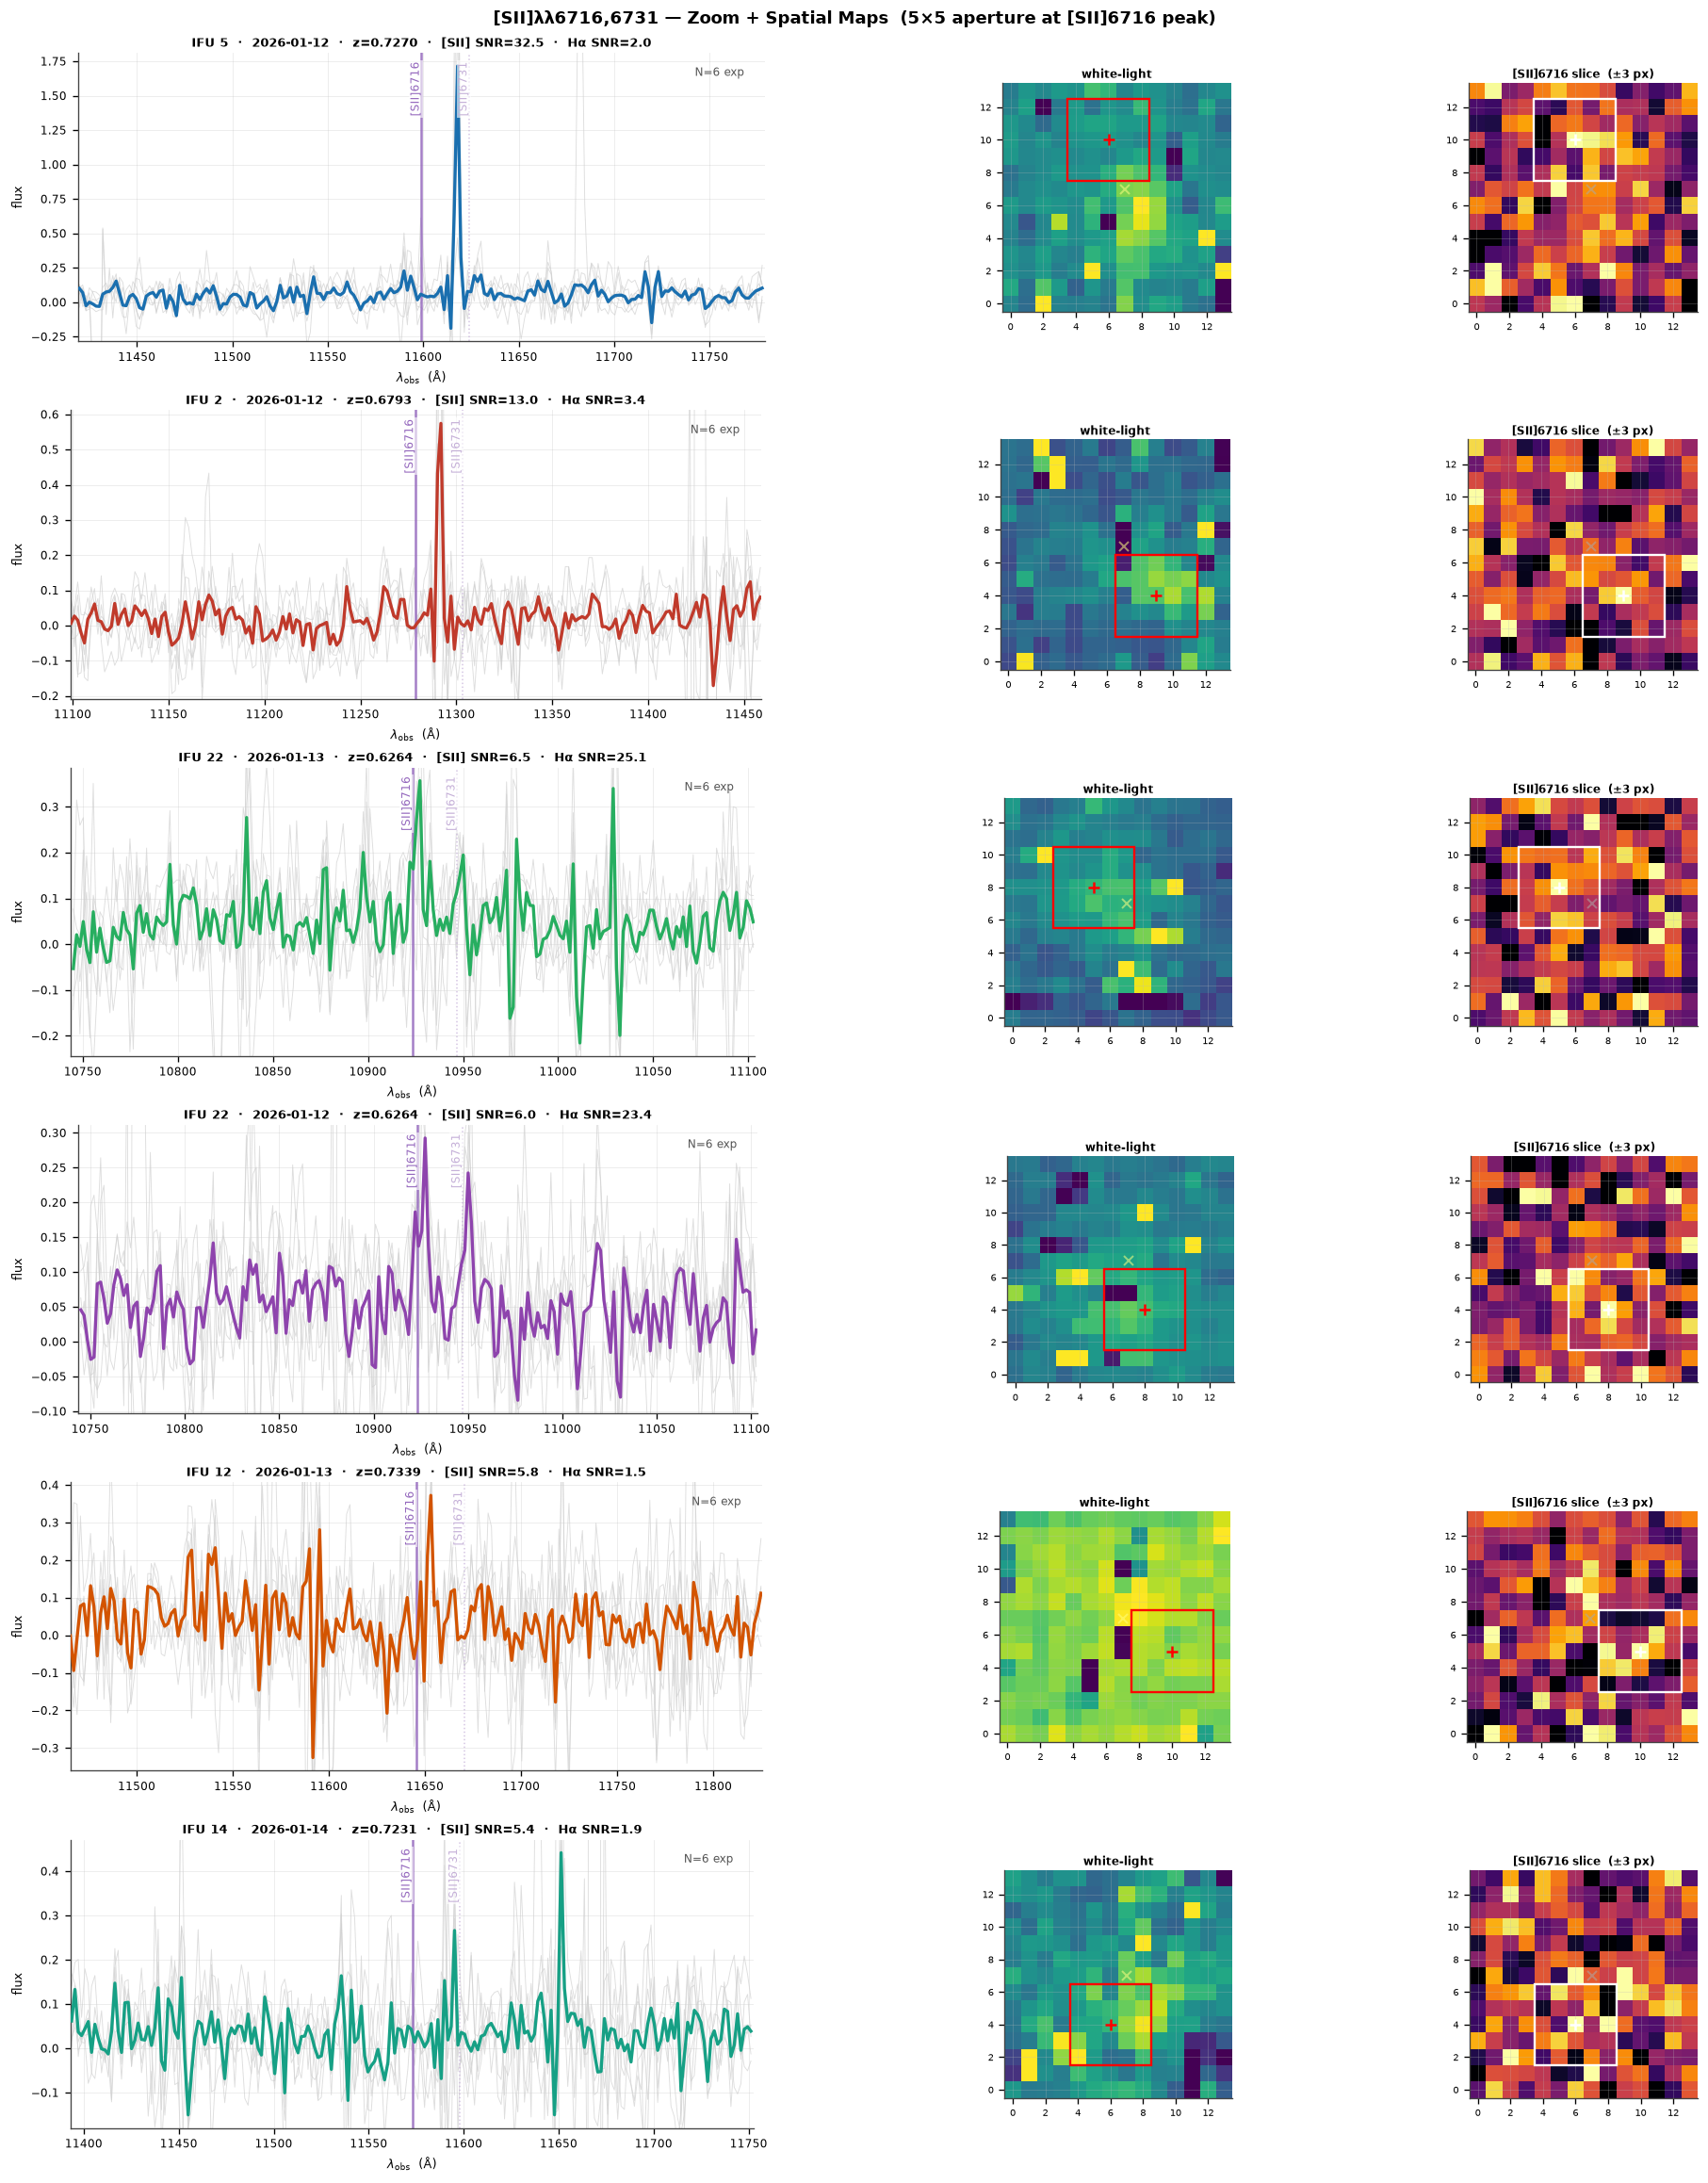

Saved → kmos_showcase_sii_detail.pdf


In [ ]:
# ── [SII]λ6716  detail view ──────────────────────────────────────────────────
n_det = min(TOP_DETAIL, len(top_sii))
if n_det == 0:
    print("No [SII] targets to display.")
else:
    fig = plt.figure(figsize=(15, n_det * 3.2), constrained_layout=True)
    fig.suptitle("[SII]λλ6716,6731 — Zoom + Spatial Maps  (5×5 aperture at [SII]6716 peak)",
                 fontsize=11, fontweight="bold")
    outer = gridspec.GridSpec(n_det, 1, figure=fig)

    for row_i, (e, color) in enumerate(zip(top_sii[:n_det], PALETTE)):
        inner = gridspec.GridSpecFromSubplotSpec(
            1, 3, subplot_spec=outer[row_i], width_ratios=[3, 1, 1], wspace=0.38)
        ax_sp = fig.add_subplot(inner[0])
        ax_wl = fig.add_subplot(inner[1])
        ax_nb = fig.add_subplot(inner[2])

        wave, z = e["wave"], e["z"]
        lam     = SII_REST * (1.0 + z)
        cy, cx  = e["sii_ctr"]
        cy_geo, cx_geo = e["ctr_geom"]
        moved   = (cy, cx) != (cy_geo, cx_geo)

        wlo, whi = lam - SII_HALF, lam + SII_HALF
        m = (wave >= wlo) & (wave <= whi)

        for s in e["spectra"]:
            ax_sp.plot(wave[m] * 1e4, s[m],
                       color="#d0d0d0", lw=0.55, alpha=0.7, zorder=1)
        ax_sp.plot(wave[m] * 1e4, e["med"][m], color=color, lw=2.0, zorder=3)

        ax_sp.axvline(lam * 1e4, color=SII_COLOR, lw=1.5, ls="-", alpha=0.85, zorder=2)
        ax_sp.text(lam * 1e4, 0.97, "[SII]6716",
                   transform=ax_sp.get_xaxis_transform(),
                   rotation=90, ha="right", va="top", fontsize=7, color=SII_COLOR,
                   bbox=dict(fc="white", ec="none", alpha=0.6, pad=1))
        for lname, (lr, lc, lw_, ls) in SII_COMP.items():
            lo = lr * (1.0 + z)
            if wlo <= lo <= whi:
                ax_sp.axvline(lo * 1e4, color=lc, lw=lw_, ls=ls, alpha=0.75, zorder=2)
                ax_sp.text(lo * 1e4, 0.97, lname,
                           transform=ax_sp.get_xaxis_transform(),
                           rotation=90, ha="right", va="top", fontsize=7, color=lc,
                           bbox=dict(fc="white", ec="none", alpha=0.6, pad=1))

        ax_sp.set_xlim(wlo * 1e4, whi * 1e4)
        vis = e["med"][m]; fv = vis[np.isfinite(vis)]
        if fv.size:
            ymin, ymax = np.nanmin(fv), np.nanmax(fv)
            pad = 0.05 * max(ymax - ymin, 0)
            ax_sp.set_ylim(ymin - pad, ymax + pad)
        ax_sp.set_title(
            f"IFU {e['ifu']}  ·  {e['ob_date']}  ·  z={z:.4f}  ·  "
            f"[SII] SNR={e['sii_snr']:.1f}  ·  Hα SNR={e['snr']:.1f}",
            fontsize=8, pad=4)
        ax_sp.set_xlabel(r"$\lambda_{\rm obs}$  (Å)", fontsize=8)
        ax_sp.set_ylabel("flux", fontsize=8)
        ax_sp.tick_params(labelsize=7)
        ax_sp.text(0.97, 0.95, f"N={e['n_exp']} exp",
                   transform=ax_sp.transAxes, ha="right", va="top",
                   fontsize=7, color="#555")

        if e["cube"] is not None:
            cube  = e["cube"]
            valid = _erode_valid(np.isfinite(cube), EDGE_MARGIN)
            wl_im = np.nansum(np.where(valid, cube, np.nan), axis=0)
            ax_wl.imshow(wl_im, origin="lower", aspect="equal", cmap="viridis",
                         vmin=np.nanpercentile(wl_im, 2), vmax=np.nanpercentile(wl_im, 98))
            _annotate_map(ax_wl, cy, cx, cy_geo, cx_geo, moved, ec="red", lc_geo="#ffff80")
            ax_wl.set_title("white-light", fontsize=7, pad=3)
            ax_wl.tick_params(labelsize=6)

            nb_im = e.get("sii_image")
            if nb_im is not None and nb_im[np.isfinite(nb_im)].size:
                fin = nb_im[np.isfinite(nb_im)]
                ax_nb.imshow(nb_im, origin="lower", aspect="equal", cmap="inferno",
                             vmin=np.nanpercentile(fin, 5), vmax=np.nanpercentile(fin, 97))
                _annotate_map(ax_nb, cy, cx, cy_geo, cx_geo, moved, ec="white", lc_geo="#aaaaaa")
                ax_nb.set_title(r"[SII]6716 slice  (±3 px)", fontsize=7, pad=3)
                ax_nb.tick_params(labelsize=6)
            else:
                ax_nb.set_visible(False)
        else:
            ax_wl.set_visible(False); ax_nb.set_visible(False)

    plt.savefig("kmos_showcase_sii_detail.pdf", bbox_inches="tight")
    plt.show()
    print("Saved → kmos_showcase_sii_detail.pdf")